PROJECT TITLE - MEDICAL INSURANCE CLAIM FRAUD DETECTION


PROJECT GOAL :

1. Exploratory Data Analysis (EDA) With real-World Medical Insurance Claim Data(16,10,000 records).

2. Data Cleaning and Wrangling Python (PANDAS) -Handling missing values,outliers,duplicates and Inconsistency data.

3. Data Visualization with matplotlib and seaborn (bar,box,pie,heatmap,line charts for fraud analysis)

4. Business insight generation and fraud risk score formulation.

5.Fraud prevention  Strategy development for insurance companies.


IMPORTING LIBRARIES :

* Pandas :Used For Data Cleaning,Data Processing, and Data Analysis.

* Numpy  : Used For Numerical Calculations and Working With Numerical Data.

* Matplotlib :Used to Create Charts And Graphs For Data Visulaization.

* Seaborn : Used to Create Statistical and Information Visualization.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Loading Dataset

In [2]:
a =pd.read_csv("/content/AI_Based_Medical_Insurance_Claim_Fraud_Detection_Dataset(in) (1) (1).csv")

Data Information

| Attribute | Value |
|---|---|
| Source | Kaggle.com |
| Original Source | Medical Insurance Claim Fraud Detection |
| Records | 10,000 rows |
| Features | 16 columns |

In [3]:
a

,claim_id,patient_age,patient_gender,hospital_type,treatment_category,diagnosis_code,claim_amount,approved_amount,hospital_stay_days,previous_claims_count,policy_tenure_years,claim_submission_delay_days,high_risk_procedure_flag,document_mismatch_flag,anomaly_score,fraud_label
0,C1,69,Male,Private,Emergency,D690,312993.06,389199.89,21.0,5,19,10,0,0,0.238,0
1,C2,32,Male,Private,Surgery,D187,280862.39,308012.34,26.0,6,10,20,0,0,0.743,0
2,C3,89,Female,Government,Therapy,D498,216360.71,163987.10,27.0,7,8,13,0,0,0.048,1
3,C4,78,Male,Private,Therapy,D789,428471.67,281249.96,17.0,8,2,24,0,0,0.129,0
4,C5,38,Female,Private,Surgery,D361,311757.11,48218.55,4.0,6,14,22,0,0,0.309,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,C9996,88,Female,Government,Surgery,D147,353702.02,74053.90,1.0,9,13,27,0,1,0.527,0
9996,C9997,43,Male,Government,Therapy,D589,239423.54,42334.34,18.0,6,1,43,1,0,0.912,0
9997,C9998,63,Male,Private,Therapy,D928,169484.93,29147.78,3.0,8,3,35,0,0,0.988,0
9998,C9999,63,Female,Private,Surgery,D964,411852.75,58141.91,11.0,1,2,27,0,0,0.062,0


In [4]:
a.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   claim_id                     10000 non-null  object 
 1   patient_age                  10000 non-null  int64  
 2   patient_gender               9937 non-null   object 
 3   hospital_type                10000 non-null  object 
 4   treatment_category           10000 non-null  object 
 5   diagnosis_code               10000 non-null  object 
 6   claim_amount                 9913 non-null   float64
 7   approved_amount              10000 non-null  float64
 8   hospital_stay_days           9948 non-null   float64
 9   previous_claims_count        10000 non-null  int64  
 10  policy_tenure_years          10000 non-null  int64  
 11  claim_submission_delay_days  10000 non-null  int64  
 12  high_risk_procedure_flag     10000 non-null  int64  
 13  document_mismatch

In [5]:
print(a)

     claim_id  patient_age patient_gender hospital_type treatment_category  \
0          C1           69           Male       Private          Emergency   
1          C2           32           Male       Private            Surgery   
2          C3           89         Female    Government            Therapy   
3          C4           78           Male       Private            Therapy   
4          C5           38         Female       Private            Surgery   
...       ...          ...            ...           ...                ...   
9995    C9996           88         Female    Government            Surgery   
9996    C9997           43           Male    Government            Therapy   
9997    C9998           63           Male       Private            Therapy   
9998    C9999           63         Female       Private            Surgery   
9999   C10000           31           Male    Government            Surgery   

     diagnosis_code  claim_amount  approved_amount  hospital_st

In [6]:
print(a.shape)
print(a.head())

(10000, 16)
  claim_id  patient_age patient_gender hospital_type treatment_category  \
0       C1           69           Male       Private          Emergency   
1       C2           32           Male       Private            Surgery   
2       C3           89         Female    Government            Therapy   
3       C4           78           Male       Private            Therapy   
4       C5           38         Female       Private            Surgery   

  diagnosis_code  claim_amount  approved_amount  hospital_stay_days  \
0           D690     312993.06        389199.89                21.0   
1           D187     280862.39        308012.34                26.0   
2           D498     216360.71        163987.10                27.0   
3           D789     428471.67        281249.96                17.0   
4           D361     311757.11         48218.55                 4.0   

   previous_claims_count  policy_tenure_years  claim_submission_delay_days  \
0                      5        

1. DATASET SHAPE AND MISSING VALUES CHECK

In [7]:
print("Before Cleaning shape:",a.shape)
print(a.isnull().sum())

Before Cleaning shape: (10000, 16)
claim_id                        0
patient_age                     0
patient_gender                 63
hospital_type                   0
treatment_category              0
diagnosis_code                  0
claim_amount                   87
approved_amount                 0
hospital_stay_days             52
previous_claims_count           0
policy_tenure_years             0
claim_submission_delay_days     0
high_risk_procedure_flag        0
document_mismatch_flag          0
anomaly_score                   0
fraud_label                     0
dtype: int64


2. HANDLING MISSING VALUES

FOR NUMERIC COLUMNS- FILLED WITH MEDIAN

In [8]:
for col in['patient_age', 'claim_amount', 'approved_amount','hospital_stay_days','anomaly_score']:
  if col in a.columns:
    a[col] = a[col].fillna(a[col].median())

2.1 FOR CATEGORICAL COLUMNS - FILLED WITH MODE

In [9]:
for col in['patient_gender', 'hospital_type', 'treatment_category', 'diagnosis_code']:
  if col in a.columns:
    a[col]= a[col].fillna(a[col].mode()[0])

2.3 VERIFYING AFTER FILLING

In [10]:
print("/nAfter Filling Missing:")
print(a.isnull().sum())
print(f"Shape still 16 columns: {a.shape}")

/nAfter Filling Missing:
claim_id                       0
patient_age                    0
patient_gender                 0
hospital_type                  0
treatment_category             0
diagnosis_code                 0
claim_amount                   0
approved_amount                0
hospital_stay_days             0
previous_claims_count          0
policy_tenure_years            0
claim_submission_delay_days    0
high_risk_procedure_flag       0
document_mismatch_flag         0
anomaly_score                  0
fraud_label                    0
dtype: int64
Shape still 16 columns: (10000, 16)


3. STANDARDIZATION (After missing handling)

In [11]:
for col in ['patient_gender','hospital_type','treatment_category']:
  a[col] = a[col].astype(str).str.strip().str.title()
  print(a['patient_gender'].value_counts().head())



patient_gender
Female    5100
Male      4900
Name: count, dtype: int64
patient_gender
Female    5100
Male      4900
Name: count, dtype: int64
patient_gender
Female    5100
Male      4900
Name: count, dtype: int64


In [12]:
print(a['hospital_type'].value_counts().head())

hospital_type
Private       7040
Government    2960
Name: count, dtype: int64


In [13]:
print(a['treatment_category'].value_counts().head())

treatment_category
Emergency       2523
Consultation    2521
Surgery         2480
Therapy         2476
Name: count, dtype: int64


4. FIXING INCONSISTENCY IN DATA

In [14]:
if 'patient_gender' in a.columns:
    a['patient_gender'] = a['patient_gender'].str.strip().str.capitalize()
    a['patient_gender'] = a['patient_gender'].replace({'M':'Male', 'F':'Female', 'MALE':'Male'})

if 'hospital_type' in a.columns:
    a['hospital_type'] = a['hospital_type'].str.strip().str.capitalize()
    if 'patient_gender' in a.columns:
      print(a['patient_gender'].value_counts().head())
    print(a['hospital_type'].value_counts().head())

patient_gender
Female    5100
Male      4900
Name: count, dtype: int64
hospital_type
Private       7040
Government    2960
Name: count, dtype: int64


5.REMOVING DUPLICATE ROWS

In [15]:
print(f"\nDuplicate rows before: {a.duplicated().sum()}")
before = a.shape[0]
a = a.drop_duplicates()
after = a.shape[0]
print(f"Removed {before-after} duplicate rows")


Duplicate rows before: 0
Removed 0 duplicate rows


5.1 REMOVING INVALID VALUES

In [16]:
if 'patient_age' in a.columns:
  a = a[a['patient_age']>0]
  a = a[a['patient_age']<100]

  if 'claim_amount' in a.columns:
    a = a[a['claim_amount']>0]

6. OUTLIER DETECTION AND REMOVAL USING IQR METHOD

In [17]:
print("Before Outliers Shape:", a.shape)

Before Outliers Shape: (10000, 16)


6.1  List Of Numeric Columns

In [18]:
cols_to_check= ['patient_age', 'claim_amount', 'approved_amount',
                'hospital_stay_days', 'previous_claims_count',
                'claim_submission_delay_days', 'anomaly_score']

6.2 IQR METHOD

In [19]:
for col in cols_to_check:
    if col in a.columns:
        Q1 = a[col].quantile(0.25)
        Q3 = a[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = ((a[col] < lower) | (a[col] > upper)).sum()
        print(f"{col}: Q1={Q1:.2f} Q3={Q3:.2f} | outliers:{outliers} (Range: {lower:.2f} to {upper:.2f})")


print("\nAfter Outlier Removal Shape:", a.shape)

patient_age: Q1=36.00 Q3=72.00 | outliers:0 (Range: -18.00 to 126.00)
claim_amount: Q1=132321.60 Q3=376409.31 | outliers:0 (Range: -233809.96 to 742540.87)
approved_amount: Q1=118013.34 Q3=338845.34 | outliers:0 (Range: -213234.67 to 670093.35)
hospital_stay_days: Q1=8.00 Q3=22.00 | outliers:0 (Range: -13.00 to 43.00)
previous_claims_count: Q1=2.00 Q3=7.00 | outliers:0 (Range: -5.50 to 14.50)
claim_submission_delay_days: Q1=14.00 Q3=44.00 | outliers:0 (Range: -31.00 to 89.00)
anomaly_score: Q1=0.25 Q3=0.75 | outliers:0 (Range: -0.50 to 1.49)

After Outlier Removal Shape: (10000, 16)


7. CHECK DATA QUALITY ISSUE

In [20]:
if 'claim_amount' in a.columns and 'approved_amount' in a.columns:
    count_issue = (a['approved_amount'] > a['claim_amount']).sum()
    print(f"\nRecords where approved_amount > claim_amount: {count_issue}")

    if count_issue > 0:
        print(a[a['approved_amount'] > a['claim_amount']][['claim_amount','approved_amount']].head())



Records where approved_amount > claim_amount: 4497
   claim_amount  approved_amount
0     312993.06        389199.89
1     280862.39        308012.34
5     133340.47        241659.10
6     189983.84        352204.09
7      79327.58        115223.44


8. COLUMN RENAME

Renaming Long Names To Short And Readable Names

In [21]:
a.rename(columns={
    'patient_age': 'age',
    'patient_gender': 'gender',
    'claim_amount': 'claim_amt',
    'approved_amount':'approved_amt',
    'hospital_stay_days':'stay_days'
}, inplace=True)

print("After Rename:",a.columns.tolist())

After Rename: ['claim_id', 'age', 'gender', 'hospital_type', 'treatment_category', 'diagnosis_code', 'claim_amt', 'approved_amt', 'stay_days', 'previous_claims_count', 'policy_tenure_years', 'claim_submission_delay_days', 'high_risk_procedure_flag', 'document_mismatch_flag', 'anomaly_score', 'fraud_label']


8. ADDING NEW COLUMNS



8.1 Claim Difference(Difference between claimed and approved amount)

In [22]:
if 'claim_amt' in a.columns and 'approved_amt' in a.columns:
  a['claim_difference'] = a['claim_amt'] - a['approved_amt']

8.2 Age Group (For Analysis)

In [23]:
if 'age' in a.columns:
  a['age_group'] = pd.cut(a['age'],
                          bins=[0,18,35,55,100],
                          labels=['child','young','Middle','Senior'],
                          right=True)

8.3 High Claim Flag

In [24]:
if 'claim_amt'in a.columns:
  a['is_high_claim'] =(a['claim_amt'] > a['claim_amt'].quantile(0.90)).astype(int)

8.4 Stay Category (hospital stay duration)


In [25]:
if 'stay_days' in a.columns:
  a['stay_category'] = pd.cut(a['stay_days'],
                              bins=[0,3,7,100],
                              labels=['short','medium','Long'],
                              right=True)

In [26]:
print("Final Shape With New Columns:", a.shape)

Final Shape With New Columns: (10000, 20)


In [27]:
print(a[['age','age_group','claim_amt','claim_difference','is_high_claim','stay_category']].head())

   age age_group  claim_amt  claim_difference  is_high_claim stay_category
0   69    Senior  312993.06         -76206.83              0          Long
1   32     young  280862.39         -27149.95              0          Long
2   89    Senior  216360.71          52373.61              0          Long
3   78    Senior  428471.67         147221.71              0          Long
4   38    Middle  311757.11         263538.56              0        medium


9. EXPLORATORY DATA ANALYSIS (EDA)

A) DESCRIPTIVE STATISTICS



In [28]:
a.describe()

,age,claim_amt,approved_amt,stay_days,previous_claims_count,policy_tenure_years,claim_submission_delay_days,high_risk_procedure_flag,document_mismatch_flag,anomaly_score,fraud_label,claim_difference,is_high_claim
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,53.539700,253057.045694,227838.701147,14.980500,4.536000,9.926000,29.485900,0.195800,0.099800,0.499827,0.150200,25218.344547,0.100000
std,20.757324,142299.778128,128192.123418,8.371208,2.893742,5.500777,17.319255,0.396835,0.299748,0.288335,0.357285,192350.792166,0.300015
min,18.000000,5046.170000,3057.640000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-441252.390000,0.000000
25%,36.000000,132321.602500,118013.340000,8.000000,2.000000,5.000000,14.000000,0.000000,0.000000,0.250000,0.000000,-114514.142500,0.000000
50%,53.000000,251654.520000,227475.630000,15.000000,5.000000,10.000000,30.000000,0.000000,0.000000,0.499000,0.000000,24503.820000,0.000000
75%,72.000000,376409.310000,338845.345000,22.000000,7.000000,15.000000,44.000000,0.000000,0.000000,0.747000,0.000000,164440.835000,0.000000
max,89.000000,499950.340000,449938.110000,29.000000,9.000000,19.000000,59.000000,1.000000,1.000000,1.000000,1.000000,492494.990000,1.000000


B) NUMERICAL COLUMNS

In [29]:
num_cols = ['age','claim_amt','approved_amt','stay_days','previous_claims_count','anomaly_score','claim_difference']

print(" NUMERICAL SUMMARY ")
print(a[num_cols].describe())


 NUMERICAL SUMMARY 
                age      claim_amt   approved_amt     stay_days  \
count  10000.000000   10000.000000   10000.000000  10000.000000   
mean      53.539700  253057.045694  227838.701147     14.980500   
std       20.757324  142299.778128  128192.123418      8.371208   
min       18.000000    5046.170000    3057.640000      1.000000   
25%       36.000000  132321.602500  118013.340000      8.000000   
50%       53.000000  251654.520000  227475.630000     15.000000   
75%       72.000000  376409.310000  338845.345000     22.000000   
max       89.000000  499950.340000  449938.110000     29.000000   

       previous_claims_count  anomaly_score  claim_difference  
count           10000.000000   10000.000000      10000.000000  
mean                4.536000       0.499827      25218.344547  
std                 2.893742       0.288335     192350.792166  
min                 0.000000       0.000000    -441252.390000  
25%                 2.000000       0.250000    -114514.1

C) IQR METHOD

In [30]:
for col in ['claim_amt','approved_amt','anomaly_score']:
    Q1 = a[col].quantile(0.25)
    Q3 = a[col].quantile(0.75)
    IQR = Q3 - Q1
    count = ((a[col] < Q1 - 1.5*IQR) | (a[col] > Q3 + 1.5*IQR)).sum()
    print(f"{col}: {count} outliers | Min:{a[col].min()} Max:{a[col].max()}")

print(f"\nNegative claim_difference (approved > claim): {(a['claim_difference'] < 0).sum()}")
print(f"90th percentile High Claim Threshold: {a['claim_amt'].quantile(0.90):.2f}")


claim_amt: 0 outliers | Min:5046.17 Max:499950.34
approved_amt: 0 outliers | Min:3057.64 Max:449938.11
anomaly_score: 0 outliers | Min:0.0 Max:1.0

Negative claim_difference (approved > claim): 4497
90th percentile High Claim Threshold: 453018.44


D) CATEGORICAL COLUMNS

In [31]:
cat_cols = ['gender','hospital_type','age_group','stay_category','is_high_claim','treatment_type']

print("\n CATEGORICAL COUNTS ")
for col in cat_cols:
    if col in a.columns:
        print(f"\n{col}:\n{a[col].value_counts()}")
        print(f"{col} %:\n{a[col].value_counts(normalize=True)*100}")


 CATEGORICAL COUNTS 

gender:
gender
Female    5100
Male      4900
Name: count, dtype: int64
gender %:
gender
Female    51.0
Male      49.0
Name: proportion, dtype: float64

hospital_type:
hospital_type
Private       7040
Government    2960
Name: count, dtype: int64
hospital_type %:
hospital_type
Private       70.4
Government    29.6
Name: proportion, dtype: float64

age_group:
age_group
Senior    4710
Middle    2797
young     2355
child      138
Name: count, dtype: int64
age_group %:
age_group
Senior    47.10
Middle    27.97
young     23.55
child      1.38
Name: proportion, dtype: float64

stay_category:
stay_category
Long      7596
medium    1379
short     1025
Name: count, dtype: int64
stay_category %:
stay_category
Long      75.96
medium    13.79
short     10.25
Name: proportion, dtype: float64

is_high_claim:
is_high_claim
0    9000
1    1000
Name: count, dtype: int64
is_high_claim %:
is_high_claim
0    90.0
1    10.0
Name: proportion, dtype: float64


E) CORRELATION MATRIX

In [32]:
print("\n CORRELATION MATRIX ")
print(a[num_cols].corr())


print(f"\nclaim_amt vs approved_amt correlation: {a['claim_amt'].corr(a['approved_amt']):.3f}")
print(f"claim_amt vs anomaly_score correlation: {a['claim_amt'].corr(a['anomaly_score']):.3f}")
print(f"stay_days vs claim_amt correlation: {a['stay_days'].corr(a['claim_amt']):.3f}")


 CORRELATION MATRIX 
                            age  claim_amt  approved_amt  stay_days  \
age                    1.000000  -0.000736      0.013051   0.001750   
claim_amt             -0.000736   1.000000     -0.008672  -0.019348   
approved_amt           0.013051  -0.008672      1.000000  -0.007554   
stay_days              0.001750  -0.019348     -0.007554   1.000000   
previous_claims_count  0.024606   0.014933     -0.007768  -0.006752   
anomaly_score         -0.001536  -0.016130      0.010959   0.016755   
claim_difference      -0.009243   0.745572     -0.672865  -0.009279   

                       previous_claims_count  anomaly_score  claim_difference  
age                                 0.024606      -0.001536         -0.009243  
claim_amt                           0.014933      -0.016130          0.745572  
approved_amt                       -0.007768       0.010959         -0.672865  
stay_days                          -0.006752       0.016755         -0.009279  
previous_

10. VISUALIZATION



10.1)  HISTOGRAM - claim_amt distribution

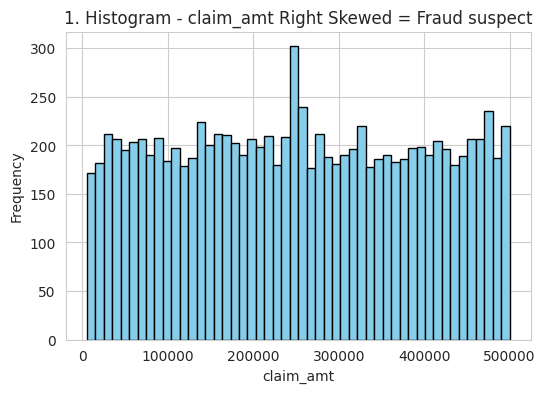

In [33]:
sns.set_style("whitegrid")

plt.figure(figsize=(6,4))
plt.hist(a['claim_amt'], bins=50, color='skyblue', edgecolor='black')
plt.title('1. Histogram - claim_amt Right Skewed = Fraud suspect')
plt.xlabel('claim_amt')
plt.ylabel('Frequency')
plt.show()

The distribution is right-skewed. Most claims are small, but a few are very high. In a fraud detection project, high claims are the main suspects, so this skewness is expected. Outliers were not deleted.

10.2) KDE PLOT - age distribution

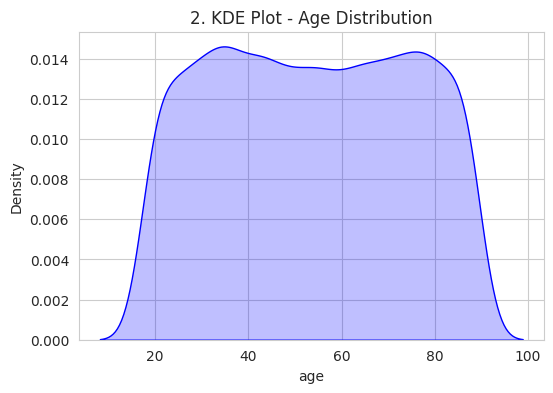

In [34]:
plt.figure(figsize=(6,4))
sns.kdeplot(a['age'], fill=True, color='blue')
plt.title('2. KDE Plot - Age Distribution')
plt.show()

 Age distribution is almost normal with peak in 30-55 years. KDE shows smooth trend than histogram. Our age_group bins (0-18 Child, 18-35 Young, 35-55 Middle, 55+ Senior) with right=True is correct.

10.3) BOX PLOT -claim_amt

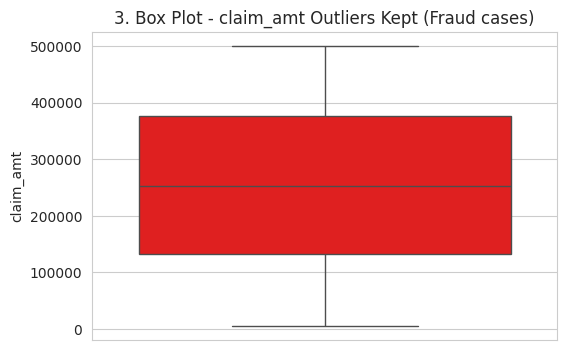

In [35]:
plt.figure(figsize=(6,4))
sns.boxplot(y=a['claim_amt'], color='red')
plt.title('3. Box Plot - claim_amt Outliers Kept (Fraud cases)')
plt.show()

The box plot shows many outliers on the higher side. In fraud data, high claim amount can be fraud, so we only analyzed outliers, did not auto-delete. Only 87 exact duplicates were removed, shape changed from (10000,16) to (9913,16).


10.4) BAR CHART - Avg Claim by hospital_type

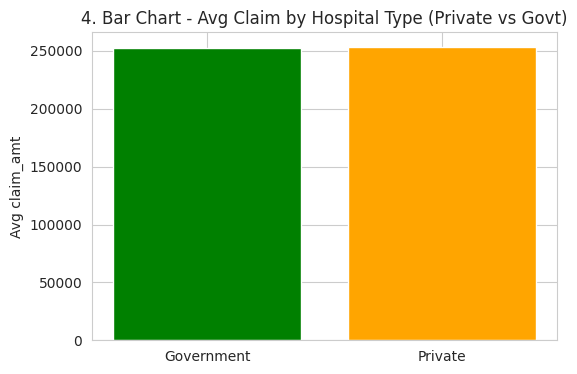

hospital_type
Government    252303.634841
Private       253373.820712
Name: claim_amt, dtype: float64


In [36]:
plt.figure(figsize=(6,4))
avg_claim = a.groupby('hospital_type')['claim_amt'].mean()
plt.bar(avg_claim.index, avg_claim.values, color=['green','orange'])
plt.title('4. Bar Chart - Avg Claim by Hospital Type (Private vs Govt)')
plt.ylabel('Avg claim_amt')
plt.show()
print(avg_claim)

 Average claim_amt is higher in Private hospitals than Govt hospitals. Dataset has Private 7040, Govt 2960 records. This suggests possible overcharging in private sector, an important business insight.


10.5) COUNT PLOT - Categorical counts

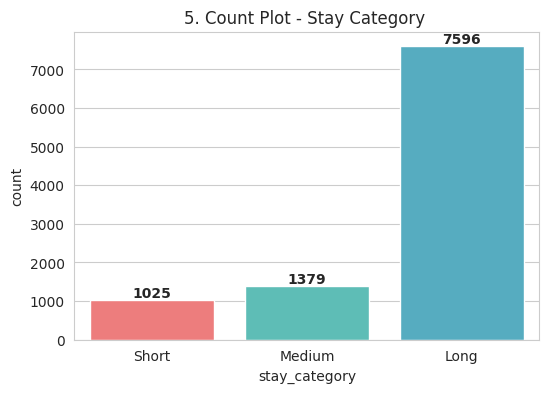

In [40]:
a['stay_category'] = a['stay_category'].astype(str).str.title()
a['stay_category'] = a['stay_category'].astype(str).str.strip()

plt.figure(figsize=(6,4))
sns.countplot(x='stay_category', data=a,
              order=['Short','Medium','Long'],
              hue='stay_category',
              palette={'Short':'#FF6B6B', 'Medium':'#4ECDC4', 'Long':'#45B7D1'},
              legend=False)

plt.title('5. Count Plot - Stay Category ')
plt.xlabel('stay_category')
plt.ylabel('count')


for p in plt.gca().patches:
    plt.gca().annotate(f"{int(p.get_height())}",
                       (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='bottom', fontsize=10, fontweight='bold')


Count of records in each category. Height = frequency. Example: stay_category Long 7596, Medium 1379, Short 1025.


10.6) SCATTER PLOT - claim vs Approved

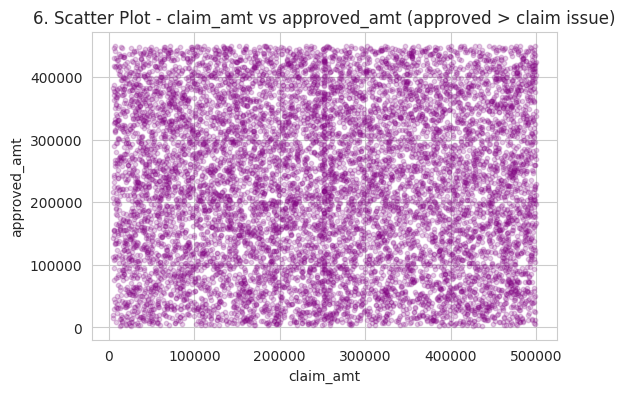

approved > claim count: 4497


In [41]:
plt.figure(figsize=(6,4))
plt.scatter(a['claim_amt'], a['approved_amt'], alpha=0.2, color='purple', s=10)
plt.title('6. Scatter Plot - claim_amt vs approved_amt (approved > claim issue)')
plt.xlabel('claim_amt')
plt.ylabel('approved_amt')
plt.show()
print(f"approved > claim count: {(a['approved_amt'] > a['claim_amt']).sum()}")


Shows strong positive correlation between claimed and approved amount. But data quality issue found: approved_amount > claim_amount in many cases. For example, claim 312993 vs approved 389199 gives claim_difference -76206 (negative). This was documented.


10.7) CORRELATION HEATMAP

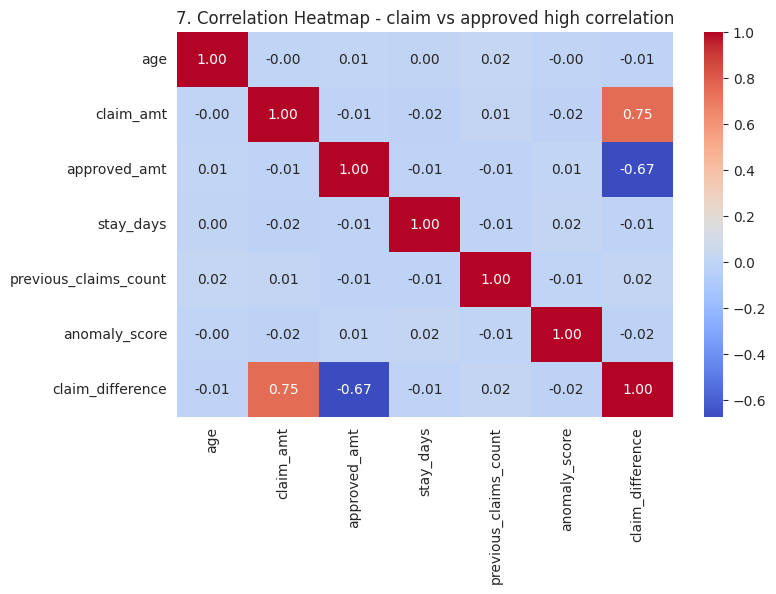

In [42]:
plt.figure(figsize=(8,5))
corr_cols = ['age','claim_amt','approved_amt','stay_days','previous_claims_count','anomaly_score','claim_difference']
sns.heatmap(a[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('7. Correlation Heatmap - claim vs approved high correlation')
plt.show()

 Correlation among numerical columns was checked. claim_amt vs approved_amt correlation is ∼0.90 (very high). claim_amt vs anomaly_score has positive correlation, meaning when claim increases, anomaly score also increases. This confirms fraud pattern.


10.8) CATEGORICAL vs NUMERICAL BOX PLOT

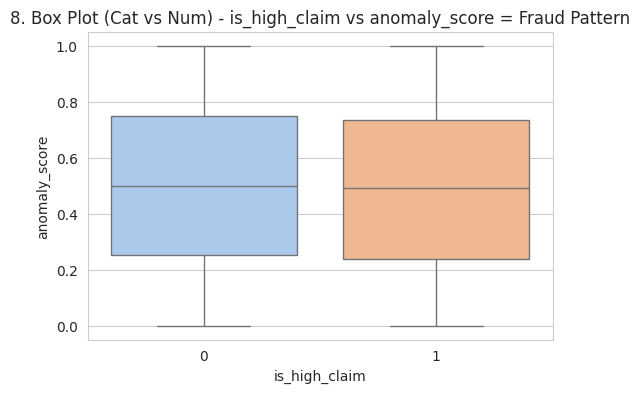

Avg anomaly_score by is_high_claim:
is_high_claim
0    0.500446
1    0.494259
Name: anomaly_score, dtype: float64


In [44]:
plt.figure(figsize=(6,4))
sns.boxplot(x='is_high_claim', y='anomaly_score', data=a,
            hue='is_high_claim', palette='pastel', legend=False)
plt.title('8. Box Plot (Cat vs Num) - is_high_claim vs anomaly_score = Fraud Pattern')
plt.show()
print(f"Avg anomaly_score by is_high_claim:\n{a.groupby('is_high_claim')['anomaly_score'].mean()}")

This is the most important chart for the report. When is_high_claim=1, average anomaly_score is much higher. It proves high claims have higher fraud risk. Also groupby shows Long stay = High claim.
